# 131. Palindrome Partitioning
**Difficulty:** 🟡 Medium · **Topic:** Backtracking · **Pattern:** [Partition and Placement](README.md) · **LeetCode:** https://leetcode.com/problems/palindrome-partitioning/

## 💡 Concepts

**Core concept(s):** **backtracking over cut positions** — build the answer one piece at a time, where each step chooses *where the next piece ends*.

**Why it applies here:**
- A partition of `s` is a sequence of decisions: "the first piece is `s[0:end]`", then "the next piece starts at `end`", and so on.
- Each decision has a cheap local test (is this piece a palindrome?), so a bad piece can be rejected **before** anything is built on top of it.
- We must return **every** valid partition, so we must explore every branch that survives the test.

**Key intuition:**
- Stand at index `start`. Try every possible end for the next piece: `s[start:start+1]`, `s[start:start+2]`, ...
- If the piece is a palindrome, take it (choose), solve the rest of the string from `end` (explore), then give it back (un-choose).
- When `start` reaches the end of the string, the pieces taken so far form one complete answer.

---

### 📚 What is a Palindrome?
- A **palindrome** reads the same forwards and backwards: `"a"`, `"aa"`, `"aba"`, `"racecar"`.
- Every single character is a palindrome, so at least one partition (all single letters) always exists.
- **Check:** compare the string with its reverse, `p == p[::-1]` — **O(k)** for a piece of length `k`.

### 📚 What is Recursion / DFS?
- **Recursion** is a function that solves a problem by calling itself on a smaller part of it.
- **Depth-first search (DFS)** follows one choice all the way down before trying the next choice.
- Python keeps each pending call on the **call stack**; when a call returns, execution resumes in its caller exactly where it left off.
- **Complexity:** the stack is as deep as the longest chain of calls — here at most `n` (one call per piece).

### 📚 What is Backtracking?
- **Backtracking** is DFS over *decisions*: make a choice, recurse, then **undo** the choice and try the next one.
- The shared state (`path`, the pieces chosen so far) is modified in place, so every `append` must be matched by a `pop`.
- **Pruning:** a test placed *before* the choice skips whole sub-trees that cannot lead to an answer.
- **Record a copy:** `out.append(path[:])`, because `path` keeps changing after the answer is recorded.
- **In Python:** a nested `def backtrack(start)` that closes over `s`, `path`, and `out`.

### 📚 What is a Bitmask?
- A **bitmask** is an integer used as a row of on/off switches: bit `i` is `1` or `0`.
- A string of length `n` has `n - 1` gaps between letters; one bit per gap says "cut here" or "don't cut".
- Counting `mask` from `0` to `2^(n-1) - 1` lists every possible cut pattern exactly once.
- **Check bit `i`:** `mask >> i & 1` — **O(1)**.

### 📚 What is Dynamic Programming (a palindrome table)?
- **Dynamic programming** stores answers to small sub-problems so bigger ones can reuse them instead of recomputing.
- Here the sub-problem is "is `s[i..j]` a palindrome?": it is when `s[i] == s[j]` **and** the inside `s[i+1..j-1]` is a palindrome (or is 0 or 1 characters long).
- Filling the `n × n` table from the bottom row up takes **O(n²)** time and space; afterwards every check is an **O(1)** lookup.
- **In Python:** a list of lists, `is_pal[i][j]`.

---

**Prerequisite knowledge:**
- String slicing: `s[a:b]` is the piece from index `a` up to, not including, `b`.
- The choose → explore → un-choose loop from [Subsets](../01_Subsets/README.md) and [Combinations](../02_Combinations/README.md).

## 📝 Problem

Given a string `s`, split it into pieces so that **every piece is a palindrome**. Return **all** possible ways to do this (any order).

**Example 1**
```
s = "aab"  ->  [["a","a","b"], ["aa","b"]]

"aab" has 2 gaps:  a | a | b   -> pieces a, a, b   (all palindromes: keep)
                   aa  | b     -> pieces aa, b     (keep)
                   a | ab      -> "ab" is not a palindrome
                   aab         -> "aab" is not a palindrome
```

**Example 2**
```
s = "a"  ->  [["a"]]
```

**Constraints:** `1 <= s.length <= 16`, `s` contains only lowercase English letters.

> Three approaches: a brute force that lists every cut pattern and filters, the backtracking template (prune a piece the moment it is not a palindrome), and the same template with a precomputed palindrome table.

In [1]:
from typing import List

### Approach 1 — Brute Force: every cut pattern, then filter

**Idea:**
1. A string of length `n` has `n - 1` gaps. Each gap is either cut or not, so there are `2^(n-1)` cut patterns.
2. Count `mask` from `0` to `2^(n-1) - 1`; bit `i` set means "cut after `s[i]`".
3. Build the pieces for that mask, and keep the pattern only if **every** piece is a palindrome.

**Time complexity:** `O(n · 2^n)` — `2^(n-1)` masks, and each one builds and checks `n` characters' worth of pieces. This holds on **every** input, even when almost nothing is a palindrome.

**Space complexity:** `O(n)` extra for the pieces of one mask (output aside).

In [2]:
def partition_brute(s: str) -> List[List[str]]:
    n = len(s)
    out = []
    for mask in range(1 << (n - 1)):          # 2^(n-1) cut patterns, one bit per gap
        pieces, start = [], 0
        for i in range(n - 1):
            if mask >> i & 1:                  # bit i set: cut between s[i] and s[i+1]
                pieces.append(s[start:i + 1])
                start = i + 1
        pieces.append(s[start:])               # the last piece runs to the end of s
        if all(p == p[::-1] for p in pieces):  # test AFTER building the whole pattern
            out.append(pieces)
    return out

### Approach 2 — Backtracking: choose the next palindromic piece (pattern template)

**Idea:** the [Partition and Placement](README.md) template. The state is `start`, the index where the next piece begins.
1. If `start == len(s)`, the pieces in `path` cover the whole string: record a copy.
2. Otherwise try every end: `piece = s[start:end]` for `end = start + 1 .. len(s)`.
3. **Prune:** if `piece` is not a palindrome, skip it — nothing built on it can be valid.
4. **Choose** `path.append(piece)`, **explore** `backtrack(end)`, **un-choose** `path.pop()`.

**Time complexity:** `O(n · 2^n)` in the worst case. On `"aaa…a"` every piece is a palindrome, so all `2^(n-1)` partitions are valid and each is copied (`O(n)`). On strings with few palindromes the prune cuts almost every branch and the work is far smaller.

**Space complexity:** `O(n)` — the recursion is at most `n` calls deep and `path` holds at most `n` pieces (output aside).

In [3]:
def partition_backtrack(s: str) -> List[List[str]]:
    out, path = [], []
    def backtrack(start):
        if start == len(s):                    # every character is in some piece
            out.append(path[:])                # record a COPY: path keeps changing
            return
        for end in range(start + 1, len(s) + 1):   # where does the next piece end?
            piece = s[start:end]
            if piece != piece[::-1]:           # PRUNE: not a palindrome
                continue
            path.append(piece)                 # CHOOSE
            backtrack(end)                     # EXPLORE: the next piece starts at end
            path.pop()                         # UN-CHOOSE
    backtrack(0)
    return out

### Approach 3 — Backtracking + palindrome table (O(1) checks)

**Idea:** the same backtracking, but every palindrome test becomes a table lookup.
1. Fill `is_pal[i][j]` (is `s[i..j]` a palindrome, both ends inclusive) from `i = n-1` down to `0`: `s[i] == s[j]` and (`j - i < 2` or `is_pal[i+1][j-1]`).
2. Run the template, but replace `piece == piece[::-1]` with `is_pal[start][end]` (here `end` is inclusive).

**Time complexity:** `O(n · 2^n)` — the table costs `O(n²)` once; the search is the same as Approach 2, and copying the output still dominates in the worst case.

**Space complexity:** `O(n²)` for the table, plus `O(n)` for the recursion and `path`.

> The table removes the `O(k)` reversal from each check. It does not change the worst case, because the output itself has `2^(n-1)` partitions on `"aaa…a"`. This is the standard follow-up when an interviewer asks "can you make the check cheaper?".

In [4]:
def partition_backtrack_dp(s: str) -> List[List[str]]:
    n = len(s)
    is_pal = [[False] * n for _ in range(n)]   # is_pal[i][j]: s[i..j] (inclusive) is a palindrome
    for i in range(n - 1, -1, -1):             # bottom-up: row i needs row i+1
        for j in range(i, n):
            is_pal[i][j] = s[i] == s[j] and (j - i < 2 or is_pal[i + 1][j - 1])
    out, path = [], []
    def backtrack(start):
        if start == n:
            out.append(path[:])
            return
        for end in range(start, n):            # end is INCLUSIVE here
            if not is_pal[start][end]:         # PRUNE with an O(1) lookup
                continue
            path.append(s[start:end + 1])      # CHOOSE
            backtrack(end + 1)                 # EXPLORE
            path.pop()                         # UN-CHOOSE
    backtrack(0)
    return out

In [5]:
# Correctness check
import random

tests = [
    ("aab",  [["a", "a", "b"], ["aa", "b"]]),                         # LeetCode example 1
    ("a",    [["a"]]),                                                # LeetCode example 2
    ("ab",   [["a", "b"]]),                                           # no multi-letter palindrome
    ("aba",  [["a", "b", "a"], ["aba"]]),                             # whole string is a palindrome
    ("aaa",  [["a", "a", "a"], ["a", "aa"], ["aa", "a"], ["aaa"]]),   # every cut works: 2^(3-1) = 4
    ("abba", [["a", "b", "b", "a"], ["a", "bb", "a"], ["abba"]]),
]
for s, exp in tests:
    a, b, c = partition_brute(s), partition_backtrack(s), partition_backtrack_dp(s)
    print(f"{s!r:7} -> {b}")
    assert sorted(a) == sorted(b) == sorted(c) == sorted(exp), f"mismatch on {s!r}"
    assert all("".join(p) == s for p in b)                 # every partition reassembles s

# Randomised cross-check: all three approaches agree on many random strings
rng = random.Random(131)
for _ in range(300):
    s = "".join(rng.choice("ab") for _ in range(rng.randint(1, 12)))
    assert sorted(partition_brute(s)) == sorted(partition_backtrack(s)) == sorted(partition_backtrack_dp(s)), s
print("300 random strings: all three approaches agree")

# "aaa...a": every one of the 2^(n-1) cut patterns is valid
assert all(len(partition_backtrack("a" * n)) == 2 ** (n - 1) for n in range(1, 11))
print("\nAll tests passed")

'aab'   -> [['a', 'a', 'b'], ['aa', 'b']]
'a'     -> [['a']]
'ab'    -> [['a', 'b']]
'aba'   -> [['a', 'b', 'a'], ['aba']]
'aaa'   -> [['a', 'a', 'a'], ['a', 'aa'], ['aa', 'a'], ['aaa']]
'abba'  -> [['a', 'b', 'b', 'a'], ['a', 'bb', 'a'], ['abba']]
300 random strings: all three approaches agree

All tests passed


## ⏱️ Empirically Checking the Complexities

Big-O can't be read off a function directly, but it can be **measured**. For linear or quadratic code we double `n` and read the ratio. Here the output itself can have `2^(n-1)` partitions, so doubling `n` would square the runtime. Instead we grow `n` by **+1** and read the ratio per extra character:

| Theoretical | Ratio when `n` → `n + 1` |
|-------------|--------------------------|
| polynomial (`n`, `n²`) | ≈ **1×** (slightly above) |
| `O(2^n)` / `O(n · 2^n)` | ≈ **2×** |

(The helper's last line describes ratios for *doubling* sizes; ignore it here, since our sizes step by +1.)

**Run 1 — worst case `"a" * n`:** every piece is a palindrome, so all `2^(n-1)` partitions are valid. All three approaches must do exponential work, ≈2× per extra character.

**Run 2 — palindrome-poor `"abcabc…"`:** no piece longer than one letter is a palindrome, so there is exactly one answer. The brute force still builds all `2^(n-1)` cut patterns (≈2× per character); backtracking prunes every multi-letter piece and stays near 1×. This is the gap between "enumerate then filter" and "prune while building".

=== Run 1: worst case 'aaa...a' ===

brute O(n*2^n)
        n |  time (ms) | ratio vs prev
  ------- | ---------- | -------------
       13 |       4.91 |           n/a
       14 |      10.28 |         2.09x
       15 |      22.23 |         2.16x


       16 |      51.90 |         2.33x


       17 |     109.66 |         2.11x

backtrack O(n*2^n)
        n |  time (ms) | ratio vs prev
  ------- | ---------- | -------------
       13 |       1.58 |           n/a
       14 |       3.45 |         2.19x
       15 |       7.03 |         2.04x
       16 |      14.36 |         2.04x


       17 |      28.18 |         1.96x

backtrack+table O(n*2^n)
        n |  time (ms) | ratio vs prev
  ------- | ---------- | -------------
       13 |       1.22 |           n/a
       14 |       2.84 |         2.34x
       15 |       6.03 |         2.12x
       16 |      11.39 |         1.89x
       17 |      22.75 |         2.00x

Ratios per doubling: ~1x=>constant/log, ~2x=>linear or n log n, ~4x=>quadratic, ~8x=>cubic.


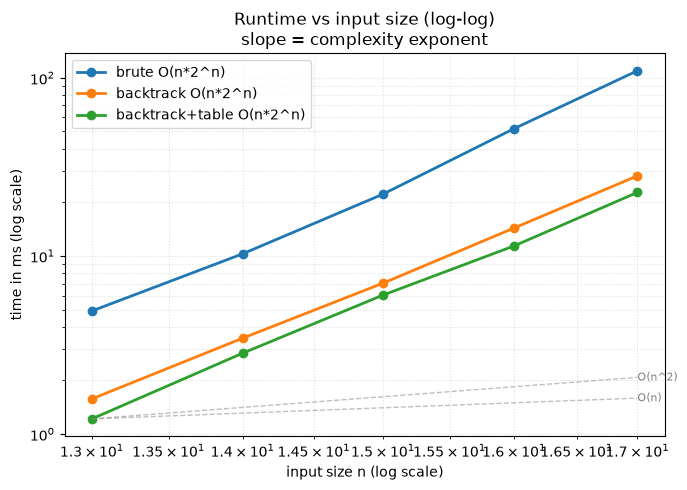


=== Run 2: palindrome-poor 'abcabc...' ===

brute O(n*2^n)
        n |  time (ms) | ratio vs prev
  ------- | ---------- | -------------
       13 |       4.43 |           n/a
       14 |       9.15 |         2.06x
       15 |      19.13 |         2.09x
       16 |      41.23 |         2.16x


       17 |      85.67 |         2.08x

backtrack O(n*2^n)
        n |  time (ms) | ratio vs prev
  ------- | ---------- | -------------
       13 |       0.01 |           n/a
       14 |       0.01 |         1.04x
       15 |       0.01 |         1.04x
       16 |       0.01 |         1.30x
       17 |       0.01 |         1.07x

backtrack+table O(n*2^n)
        n |  time (ms) | ratio vs prev
  ------- | ---------- | -------------
       13 |       0.01 |           n/a
       14 |       0.01 |         1.15x
       15 |       0.01 |         1.04x
       16 |       0.01 |         1.15x
       17 |       0.01 |         1.03x

Ratios per doubling: ~1x=>constant/log, ~2x=>linear or n log n, ~4x=>quadratic, ~8x=>cubic.


{'brute O(n*2^n)': [4.432082991115749,
  9.145624935626984,
  19.12608405109495,
  41.22733394615352,
  85.66887502092868],
 'backtrack O(n*2^n)': [0.009333016350865364,
  0.009750016033649445,
  0.010124989785254002,
  0.013125012628734112,
  0.014083110727369785],
 'backtrack+table O(n*2^n)': [0.008082948625087738,
  0.009333016350865364,
  0.009709037840366364,
  0.011208001524209976,
  0.011541997082531452]}

In [6]:
import os, sys
_root = os.getcwd()
for _ in range(5):
    if os.path.exists(os.path.join(_root, "bench_utils.py")):
        break
    _root = os.path.dirname(_root)
if _root not in sys.path:
    sys.path.insert(0, _root)
from bench_utils import benchmark

solutions = {
    "brute O(n*2^n)": partition_brute,
    "backtrack O(n*2^n)": partition_backtrack,
    "backtrack+table O(n*2^n)": partition_backtrack_dp,
}
sizes = [13, 14, 15, 16, 17]                   # +1 per step, not doubling

def make_worst_case(n):
    return ("a" * n,)                          # every cut is valid: 2^(n-1) answers

print("=== Run 1: worst case 'aaa...a' ===")
benchmark(solutions, make_worst_case, sizes, repeats=3, plot=True)

def make_palindrome_poor(n):
    return (("abc" * n)[:n],)                  # only single letters are palindromes: 1 answer

print("\n=== Run 2: palindrome-poor 'abcabc...' ===")
benchmark(solutions, make_palindrome_poor, sizes, repeats=3)

## 🧩 Patterns Learned

- **Pattern:** [Partition and Placement](README.md) — the state is the index where the next piece starts; each step chooses where that piece ends, keeps it only if it is a palindrome, recurses from `end`, then pops it.
- **Prune before you choose:** the palindrome test sits *before* `path.append`, so a bad piece never gets a sub-tree. Run 2 of the benchmark shows the effect: the brute force stays ≈2× per character while backtracking barely grows.
- **Output-sensitive worst case:** on `"aaa…a"` there are `2^(n-1)` valid answers, so no algorithm can beat `O(n · 2^n)` — the best you can do is waste nothing on invalid branches.
- **Cheaper check, same template:** precompute `is_pal[i][j]` in `O(n²)` and every test becomes `O(1)` (Approach 3).
- **Signal:** "return all ways to split / partition / segment a string such that every piece …".
- **Related problems:** Word Break II (pieces must be dictionary words), Restore IP Addresses (pieces must be 0–255), Palindrome Partitioning II (minimum cuts: a counting question, solved with DP instead), N-Queens (same choose-check-recurse shape on a board).
- **Common pitfalls:**
  1. `out.append(path)` instead of `path[:]` — every answer ends up as the same (finally empty) list.
  2. Forgetting `path.pop()` after the recursive call — pieces from one branch leak into the next.
  3. Off-by-one in the end loop: `range(start + 1, len(s) + 1)` with slicing, or `range(start, n)` with inclusive `is_pal` indices; mixing the two drops the last character.
  4. Filling `is_pal` top-down (`i` increasing) — `is_pal[i+1][j-1]` is not ready yet.